<a href="https://colab.research.google.com/github/bsheese/387/blob/main/19_onramp/19_0_Whole_Game/19_0_1_Your_First_Image_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Whole Game: Part 1
## Your First Image Model

---

## What This Notebook Is About

In this notebook you will train a deep learning model that looks at a photo of a cat or a dog and names its breed. You will do it today, before we have talked about what a neural network is, what a weight is, or how training works.

That order is on purpose. Many courses build up from the parts (one neuron, then a layer, then a network) and only show a working model near the end. This course starts the other way around, the way the fast.ai course does: first you see the whole thing working on real photos, and then the rest of the semester opens it up one piece at a time.

So for now, treat the model as a black box. You will see all of the code, and the comments say what each part does, but you are not expected to understand the code yet or to be able to write it. Here is where each part gets explained:

- **19_1** uses this model to teach how to judge whether a model is any good (baselines, splits, the confusion matrix) and shows that its last step is a single "neuron".
- **Unit 20** explains how a network learns from its mistakes.
- **Unit 21** builds the training loop you will run today, one line at a time.
- **22_1** comes back to exactly what we do here (reusing a model that someone else trained) and explains why it works.

**What you will do:**
1. Set up Colab with a GPU
2. Look at the photos: four breeds, split into training, validation and test sets
3. Load a model that was already trained on over a million photos, and see what it thinks our pets are
4. Replace the model's last layer and train it on our four breeds
5. Check it on photos it has never seen, including (if you like) a photo of your own

---

## Section 1: Setting Up Colab

Colab runs this notebook on a computer at Google, not on your laptop. Training a model goes much faster on a **GPU** (graphics processing unit), a chip that was designed for video games and happens to be very good at doing thousands of multiplications at the same time, which is most of what a neural network does. To ask Colab for a GPU:

1. Open the **Runtime** menu and choose **Change runtime type**
2. Under **Hardware accelerator**, choose **T4 GPU**
3. Click **Save**

Changing the runtime restarts the notebook, so do this before you run anything.

The free GPU is not always available. If Colab says it can't give you one, keep going on the CPU. Everything in this notebook still works on a CPU. The training cell in Section 4 takes a few minutes instead of under a minute, and Section 4 also has a shortcut you can use if class time is running out.

Run the next cell. It loads the libraries we need and reports whether you have a GPU. Every code cell in this notebook runs with **Shift+Enter**, and they should be run in order from top to bottom.

In [1]:
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import datasets, models
from PIL import Image

torch.manual_seed(387)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch version: {torch.__version__}')
if device == 'cuda':
    print('Using the GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, so this notebook will run on the CPU. That works; training is just slower.')

PyTorch version: 2.14.1
No GPU found, so this notebook will run on the CPU. That works; training is just slower.


---

## Section 2: The Photos

The photos come from the **Oxford-IIIT Pet dataset**, which researchers at the University of Oxford and IIIT Hyderabad put together in 2012. It has 37 breeds of cats and dogs with about 200 photos of each. We use four of them:

| Breed | Species | What to look for |
|---|---|---|
| Birman | cat | long pale coat, darker face, ears and tail, and white "gloves" on all four paws |
| Ragdoll | cat | long pale coat, darker face, ears and tail; some Ragdolls also have white paws |
| basset hound | dog | long body, short legs, very long ears, droopy face |
| beagle | dog | similar colors to a basset hound, but a shorter, more compact body and longer legs |

The breeds come in pairs that look alike. Birmans and Ragdolls are easy to mix up, even for people, and so are basset hounds and beagles. A model that can tell them apart is doing more than telling cats from dogs.

The full dataset is about 800 MB. The course keeps a copy of just these four breeds (about 17 MB) in its GitHub repository, with each photo shrunk to a more manageable size. The next cell downloads it and unzips it.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)
    return name

with zipfile.ZipFile(fetch('pets4.zip')) as z:
    z.extractall('.')

for split in ['train', 'val', 'test']:
    counts = {breed: len(os.listdir(f'pets4/{split}/{breed}')) for breed in sorted(os.listdir(f'pets4/{split}'))}
    print(f'{split:5}  {counts}')

train  {'Birman': 100, 'Ragdoll': 100, 'basset_hound': 100, 'beagle': 100}
val    {'Birman': 50, 'Ragdoll': 50, 'basset_hound': 50, 'beagle': 50}
test   {'Birman': 50, 'Ragdoll': 50, 'basset_hound': 50, 'beagle': 50}


The photos are already divided into three groups, and every breed has the same number of photos in each group:

- **train** (100 per breed): the photos the model learns from.
- **val**, short for validation (50 per breed): photos the model never learns from. We check the model on them after each round of training, to see how it does on photos it hasn't seen.
- **test** (50 per breed): photos we set aside and don't touch until the very end, for one final check.

Why there are two groups of unseen photos instead of one is the topic of 19_1_1. For today it is enough to know that a model's score on photos it learned from is not a fair measure of how well it works.

Inside each group there is one folder per breed, and the name of the folder is the **label**, the right answer for every photo inside it. Here are a few of the training photos.

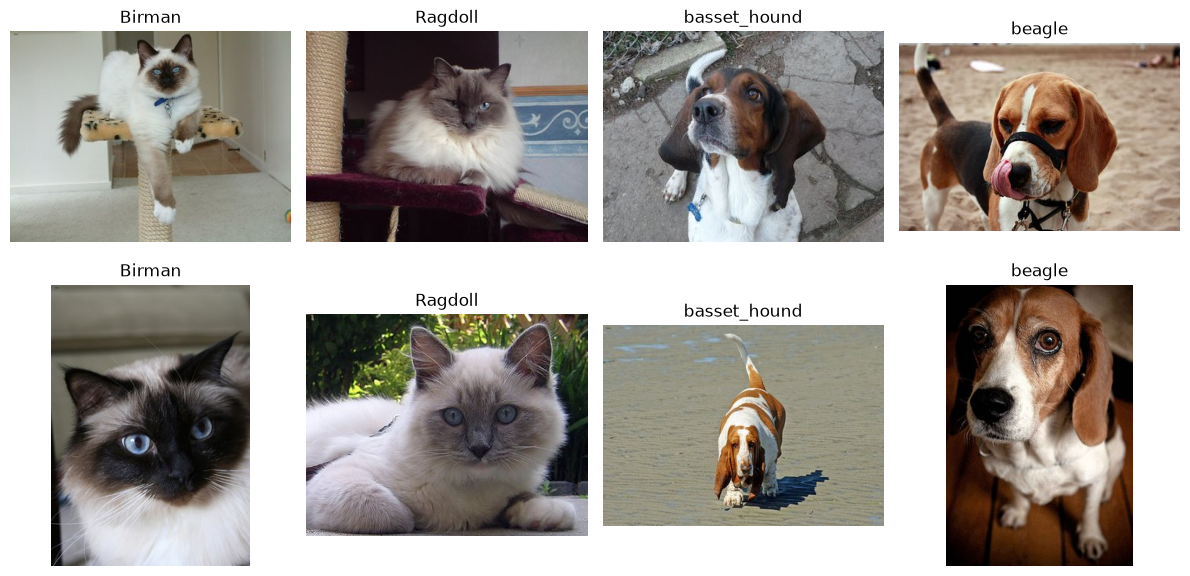

In [3]:
BREEDS = sorted(os.listdir('pets4/train'))   # ['Birman', 'Ragdoll', 'basset_hound', 'beagle']

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, breed in enumerate(BREEDS):
    files = sorted(os.listdir(f'pets4/train/{breed}'))
    for row in range(2):
        ax = axes[row, col]
        ax.imshow(Image.open(f'pets4/train/{breed}/{files[row]}'))
        ax.set_title(breed)
        ax.axis('off')
plt.tight_layout()
plt.show()

Notice how different the photos are from each other, even within one breed. They vary in pose, lighting and size, some are close-ups and some show the whole animal, and some have people or furniture in them. The model has to find what makes a beagle a beagle in spite of all of that.

---

## Section 3: A Model That Has Already Learned to See

We are not going to start from nothing. We will download a model called **ResNet-18**, which researchers at Microsoft published in 2015. It is a neural network with 18 layers, and it was trained on **ImageNet**, a collection of about 1.2 million photos sorted into 1,000 categories: everyday objects, vehicles, foods, and a lot of animals, including over 100 breeds of dog and a handful of cat breeds.

Training a model like this from scratch takes many hours on powerful GPUs. Someone has already done that work, so we can download the result in a few seconds. A model whose numbers have already been learned is called **pretrained**. Most deep learning in practice starts from a pretrained model, and this course will too.

In [4]:
weights = models.ResNet18_Weights.DEFAULT     # the numbers learned from ImageNet
model = models.resnet18(weights=weights)      # the network, filled in with those numbers
model.eval()                                  # keep the pretrained part exactly as downloaded (21_1 explains this)
model = model.to(device)

n_numbers = sum(p.numel() for p in model.parameters())
print(f'ResNet-18 has {n_numbers:,} learned numbers in it.')

ResNet-18 has 11,689,512 learned numbers in it.


Those 11 million or so numbers are the model's **weights**. Unit 20 explains what they do. For now, think of them as everything the model learned from ImageNet.

The model expects every photo in the same format that was used when it was trained: shrunk so its shorter side is 256 pixels, cropped to the 224 × 224 square in the middle, and with its colors rescaled the same way. The downloaded weights come with a function that does exactly that, so we don't have to get those details right ourselves.

In [5]:
preprocess = weights.transforms()
print(preprocess)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


Before we change anything, let's ask the pretrained model what it sees in some of our photos. It can only answer with one of its 1,000 ImageNet categories. The next cell shows one photo of each breed with the model's top three guesses and how likely it thinks each one is.

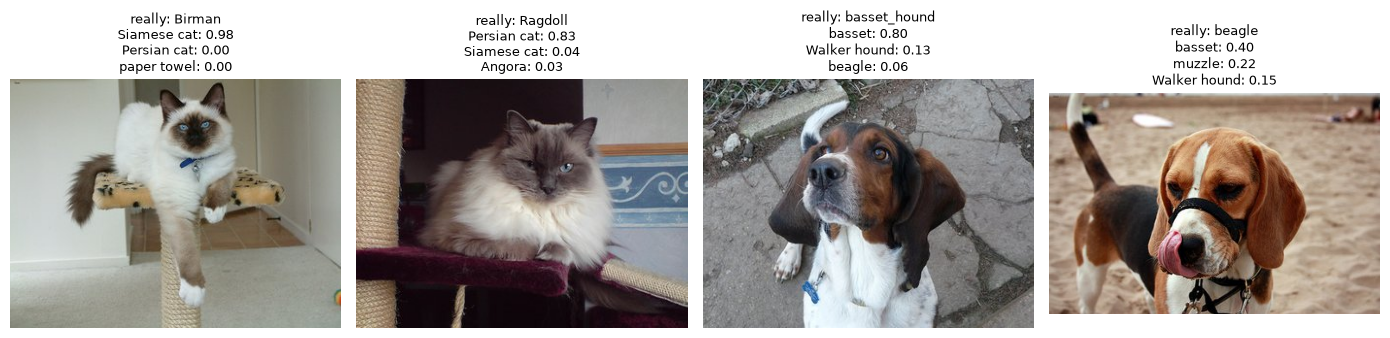

In [6]:
categories = weights.meta['categories']       # the 1,000 ImageNet category names

def imagenet_top3(path):
    x = preprocess(Image.open(path).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = model(x).softmax(dim=1)[0]
    top = probs.topk(3)
    return [(categories[i], p.item()) for p, i in zip(top.values, top.indices)]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, breed in zip(axes, BREEDS):
    path = f'pets4/train/{breed}/' + sorted(os.listdir(f'pets4/train/{breed}'))[0]
    guesses = imagenet_top3(path)
    ax.imshow(Image.open(path))
    ax.axis('off')
    ax.set_title(f'really: {breed}\n' + '\n'.join(f'{name}: {p:.2f}' for name, p in guesses), fontsize=9)
plt.tight_layout()
plt.show()

ImageNet has a "beagle" category and a "basset" category, so the pretrained model already knows something about our two dog breeds. Here it gets the basset hound right and calls the beagle a basset, which is an understandable mistake for two hounds with similar coloring. ImageNet has no Birman or Ragdoll category, so for the cats the best the model can do is a related category: it calls the Birman a "Siamese cat" and the Ragdoll a "Persian cat".

That tells us two things. The model has already learned a lot about what cats and dogs look like. What it lacks is the right set of answers for our problem. The next step keeps what it learned and replaces only the part that picks the answer.

---

## Section 4: Teaching It Our Four Breeds

The last layer of ResNet-18 receives 512 numbers that the rest of the network has computed from the photo, and turns them into 1,000 scores, one for each ImageNet category. The category with the highest score is the model's answer.

We will:

1. **Freeze** every weight the model already has, so that training can't change them.
2. **Replace the last layer** with a new one that turns the same 512 numbers into 4 scores, one per breed.
3. **Train only the new layer** on our training photos.

Adapting a pretrained model to a new task like this is called **fine-tuning**. 19_0_2 looks at the 512 numbers, and 19_1_3 shows that the new last layer is the same kind of model as logistic regression.

In [7]:
for w in model.parameters():
    w.requires_grad = False           # freeze: training will not change these

model.fc = nn.Linear(512, len(BREEDS)).to(device)   # the new last layer: 512 numbers in, 4 scores out

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Numbers that training is allowed to change: {n_trainable:,}')

Numbers that training is allowed to change: 2,052


Out of about 11 million numbers, training will only change 2,052 of them (4 × 512 = 2,048 weights plus 4 more called biases). That is why this kind of fine-tuning works with only 100 photos per breed and finishes quickly.

The new layer starts out with random numbers, so right now its answers are guesses. Training works like this:

- Show the model a **batch** of 32 training photos.
- Compare its answers with the true breeds, and measure how wrong it was. That measure is called the **loss**.
- Nudge the new layer's numbers a little in the direction that makes the right answers more likely.
- Repeat with the next batch.

One pass through all of the training photos is called an **epoch**. After each epoch we check the model's accuracy on the validation photos.

The next cell gets the photos ready for training. `IMAGES_PER_BREED` controls how many training photos of each breed the model gets to learn from. Leave it at 100 for now; the pair activity changes it.

In [8]:
IMAGES_PER_BREED = 100     # up to 100

train_data = datasets.ImageFolder('pets4/train', transform=preprocess)
val_data = datasets.ImageFolder('pets4/val', transform=preprocess)
test_data = datasets.ImageFolder('pets4/test', transform=preprocess)

# Keep the first IMAGES_PER_BREED photos of each breed
keep, seen = [], [0] * len(BREEDS)
for i, label in enumerate(train_data.targets):
    if seen[label] < IMAGES_PER_BREED:
        keep.append(i)
        seen[label] += 1
train_data = torch.utils.data.Subset(train_data, keep)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=64)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=64)

print(f'{len(train_data)} training photos, {len(val_data)} validation photos, {len(test_data)} test photos')

400 training photos, 200 validation photos, 200 test photos


Here is the training itself. This is the cell to run and watch, not to study. Unit 21 builds this loop from scratch and explains every line. On a GPU it takes well under a minute. On a CPU it takes a few minutes, and it prints a line after each epoch so you can see it working.

In [9]:
EPOCHS = 8

loss_fn = nn.CrossEntropyLoss()                                # measures how wrong the answers are
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)  # nudges the new layer's numbers

def accuracy(loader):
    # Fraction of photos in loader whose breed the model gets right
    correct = 0
    with torch.no_grad():
        for x, y in loader:
            correct += (model(x.to(device)).argmax(dim=1) == y.to(device)).sum().item()
    return correct / len(loader.dataset)

history = []
for epoch in range(1, EPOCHS + 1):
    total_loss, correct = 0.0, 0
    for x, y in train_loader:                 # one batch of 32 photos at a time
        x, y = x.to(device), y.to(device)
        scores = model(x)                     # the model's 4 scores for each photo
        loss = loss_fn(scores, y)             # how wrong were they?
        optimizer.zero_grad()
        loss.backward()                       # work out which way to nudge each number
        optimizer.step()                      # nudge them
        total_loss += loss.item() * len(y)
        correct += (scores.argmax(dim=1) == y).sum().item()
    train_acc = correct / len(train_data)
    val_acc = accuracy(val_loader)
    history.append({'epoch': epoch, 'train_loss': total_loss / len(train_data),
                    'train_acc': train_acc, 'val_acc': val_acc})
    print(f'epoch {epoch}:  training accuracy {train_acc:.3f}   validation accuracy {val_acc:.3f}')

epoch 1:  training accuracy 0.532   validation accuracy 0.715


epoch 2:  training accuracy 0.792   validation accuracy 0.880


epoch 3:  training accuracy 0.890   validation accuracy 0.890


epoch 4:  training accuracy 0.910   validation accuracy 0.900


epoch 5:  training accuracy 0.927   validation accuracy 0.910


epoch 6:  training accuracy 0.938   validation accuracy 0.900


epoch 7:  training accuracy 0.932   validation accuracy 0.895


epoch 8:  training accuracy 0.940   validation accuracy 0.890


The first epoch starts from random numbers, so its accuracy is the lowest. After that both numbers climb, and within a few epochs the model gets most of the validation photos right. The training accuracy is measured while the model is still learning during the epoch, and the validation accuracy is measured at the end of it, which is part of why the two don't match exactly. After about five epochs the validation accuracy stops improving. 19_1_1 looks at what happens when training goes on longer than that.

**Short on time, or the training was too slow?** The course keeps a copy of the new last layer, trained by this same notebook. Change `USE_COURSE_COPY` to `True` and run the cell to load it in place of yours. (19_0_2 always uses the course copy, so that everyone works with the same model.)

In [10]:
USE_COURSE_COPY = False

if USE_COURSE_COPY:
    model.fc.load_state_dict(torch.load(fetch('pets4_head.pt'), map_location=device))
    print('Loaded the course copy of the last layer.')

A plot makes the progress across epochs easier to see.

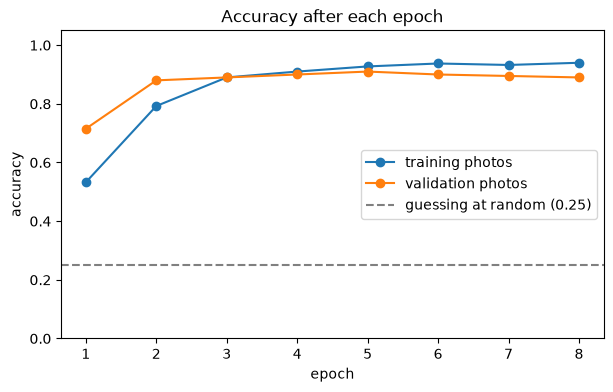

In [11]:
epochs = [h['epoch'] for h in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [h['train_acc'] for h in history], marker='o', label='training photos')
plt.plot(epochs, [h['val_acc'] for h in history], marker='o', label='validation photos')
plt.axhline(0.25, color='gray', linestyle='--', label='guessing at random (0.25)')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1.05)
plt.legend()
plt.title('Accuracy after each epoch')
plt.show()

The gray line is what you would get by guessing a breed at random: with four breeds, one guess in four is right. The model is far above that after a single epoch.

---

## Section 5: The Test Set

So far we have used the validation photos to watch training. Now we use the test photos, which the model has never seen and which we haven't looked at while making any choices. This is the number you would report if someone asked how good the model is.

In [12]:
test_acc = accuracy(test_loader)
print(f'Test accuracy: {test_acc:.3f}  ({round(test_acc * len(test_data))} of {len(test_data)} test photos right)')

Test accuracy: 0.900  (180 of 200 test photos right)


That is with only 100 training photos per breed and a few minutes of training at most. The main reason it goes so well is that we didn't start from nothing: the pretrained model had already learned from more than a million photos what edges, fur, ears and faces look like. We only had to teach it which combinations mean which of our four breeds.

Whether a test accuracy like this is actually good is a harder question than it looks. 19_1_1 compares it with a baseline and 19_1_2 breaks it down breed by breed.

---

## Section 6: Predicting on Photos It Has Never Seen

A model is only useful if you can give it a new photo and get an answer. The next cell defines a `predict` function that does that: it prepares the photo the way the model expects, runs it through the model, and turns the four scores into four probabilities that add up to 1. It then shows the photo next to the probabilities.

In [13]:
def predict(path):
    img = Image.open(path).convert('RGB')
    x = preprocess(img).unsqueeze(0).to(device)   # one photo, prepared the way the model expects
    with torch.no_grad():
        probs = model(x).softmax(dim=1)[0].cpu()  # 4 scores turned into 4 probabilities

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={'width_ratios': [1, 1.3]})
    ax1.imshow(img)
    ax1.axis('off')
    ax1.set_title(os.path.basename(path), fontsize=9)
    ax2.barh(BREEDS, probs)
    ax2.set_xlim(0, 1)
    ax2.invert_yaxis()
    ax2.set_xlabel('probability')
    ax2.set_title(f'prediction: {BREEDS[probs.argmax()]}')
    plt.tight_layout()
    plt.show()

Here it is on one test photo of each breed. The file names start with the true breed, so you can check the answers.

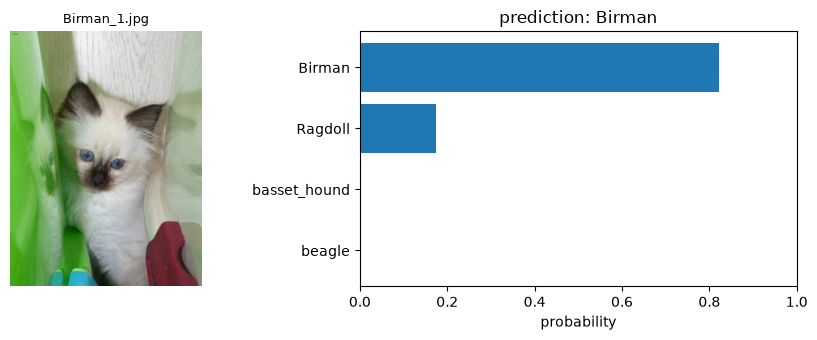

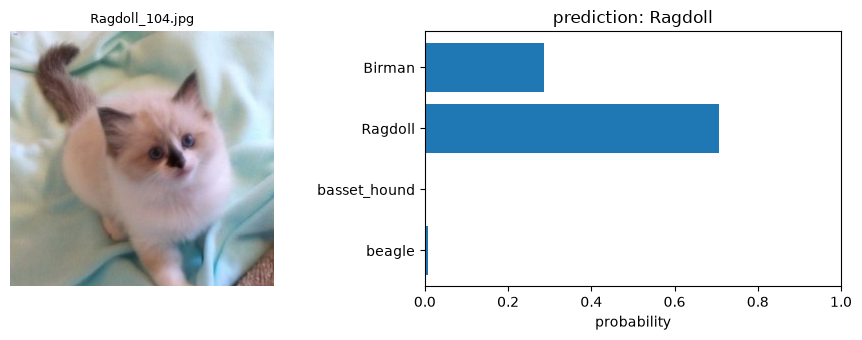

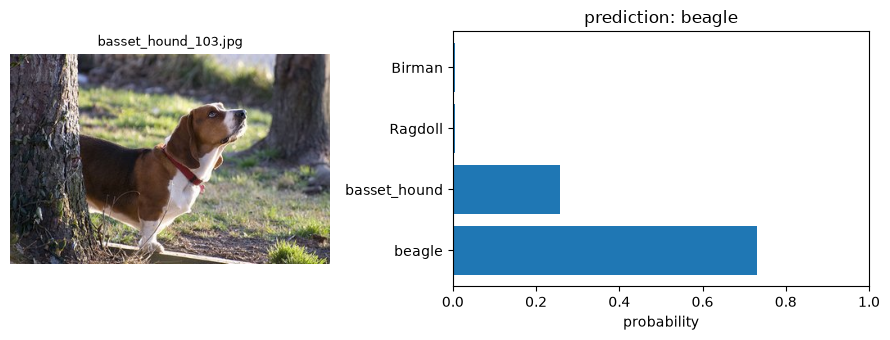

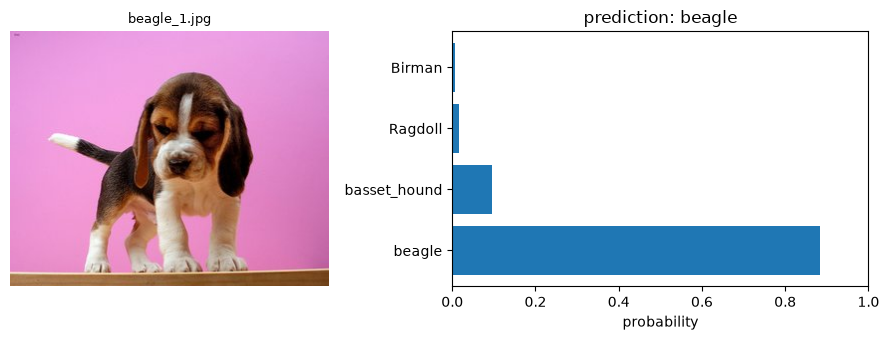

In [14]:
for breed in BREEDS:
    first_test_photo = sorted(os.listdir(f'pets4/test/{breed}'))[0]
    predict(f'pets4/test/{breed}/{first_test_photo}')

### Try It on Your Own Photo

If you have a photo of a cat or a dog on your phone or laptop, run the next cell in Colab and upload it. (It only works in Colab; anywhere else it prints a message and does nothing.)

Before you look at the result, think about what the model can and can't say. It knows exactly four breeds, so it will always answer with one of them, even for a tabby cat, a mixed-breed dog or a photo of a sandwich. 19_0_2 looks at what happens with photos that don't belong to any of the four breeds.

In [15]:
try:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        predict(name)
except ImportError:
    print('Uploading only works in Colab.')

Uploading only works in Colab.


---

## Section 7: Saving the Model

Colab deletes your files when the session ends, so the model you trained disappears unless you download it. The next cell saves the new last layer (the only part we changed) and the accuracy from each epoch. You can download them from the folder icon in Colab's left sidebar if you want to keep them, but you don't need to: the next notebook uses the course copy, which was made by running this notebook.

In [16]:
torch.save(model.fc.state_dict(), 'my_pets4_head.pt')

with open('my_pets4_history.csv', 'w') as f:
    f.write('epoch,train_loss,train_acc,val_acc\n')
    for h in history:
        f.write(f"{h['epoch']},{h['train_loss']:.4f},{h['train_acc']:.4f},{h['val_acc']:.4f}\n")

print('Saved my_pets4_head.pt and my_pets4_history.csv')

Saved my_pets4_head.pt and my_pets4_history.csv


---

## Summary

- We took **ResNet-18**, a network pretrained on the 1.2 million photos of ImageNet, and **fine-tuned** it to tell four pet breeds apart. We froze all of its weights, replaced the last layer with one that has four outputs, and trained only that layer.
- The photos were split into **training** photos (the model learns from them), **validation** photos (we check the model on them during training) and **test** photos (one final check at the end).
- Training ran for several **epochs**, each one a pass through the training photos in **batches** of 32.
- With only 100 training photos per breed, the model gets most of the test photos right. It can do that because the pretrained network already knew a great deal about what animals look like.
- The model always answers with one of its four breeds, whatever the photo shows.

**Next:** 19_0_2 looks closely at what this model gets right and wrong, how sure it is of its answers, and what it does with photos of other breeds.

**Optional:** Lesson 1 of fast.ai's [Practical Deep Learning for Coders](https://course.fast.ai/) builds a very similar model, also on day one, and explains the reasons for starting this way.